In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load Week 1 datasets
sold = pd.read_csv("../output/combined_sold_residential.csv", low_memory=False)
listings = pd.read_csv("../output/combined_listings_residential.csv", low_memory=False)

# Check dataset size and structure
print("Sold:", sold.shape)
print("Listings:", listings.shape)

sold.info()
print(sold.columns.tolist())

Sold: (397473, 84)
Listings: (547162, 84)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397473 entries, 0 to 397472
Data columns (total 84 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Flooring                      254942 non-null  object 
 1   ViewYN                        363616 non-null  object 
 2   WaterfrontYN                  248 non-null     object 
 3   BasementYN                    7775 non-null    object 
 4   PoolPrivateYN                 363046 non-null  object 
 5   OriginalListPrice             396755 non-null  float64
 6   ListingKey                    397473 non-null  int64  
 7   ListAgentEmail                396443 non-null  object 
 8   CloseDate                     397473 non-null  object 
 9   ClosePrice                    397471 non-null  float64
 10  ListAgentFirstName            394473 non-null  object 
 11  ListAgentLastName             397431 non-null  object 
 12  La

In [3]:
# Confirm Residential filtering
print("Sold property types:", sold["PropertyType"].unique())
print("Listing property types:", listings["PropertyType"].unique())

# Create missing value reports
sold_missing = pd.DataFrame({
    "Missing Count": sold.isnull().sum(),
    "Missing Percent": sold.isnull().mean() * 100
})

listing_missing = pd.DataFrame({
    "Missing Count": listings.isnull().sum(),
    "Missing Percent": listings.isnull().mean() * 100
})

# Sort by missing percentage
sold_missing = sold_missing.sort_values("Missing Percent", ascending=False)
listing_missing = listing_missing.sort_values("Missing Percent", ascending=False)

print("Sold missing values:")
print(sold_missing.head(20))

print("Listing missing values:")
print(listing_missing.head(20))

Sold property types: ['Residential']
Listing property types: ['Residential']
Sold missing values:
                              Missing Count  Missing Percent
TaxYear                              397473       100.000000
FireplacesTotal                      397473       100.000000
TaxAnnualAmount                      397473       100.000000
AboveGradeFinishedArea               397473       100.000000
ElementarySchoolDistrict             397473       100.000000
BusinessType                         397473       100.000000
CoveredSpaces                        397473       100.000000
MiddleOrJuniorSchoolDistrict         397473       100.000000
WaterfrontYN                         397225        99.937606
BelowGradeFinishedArea               395184        99.424112
BasementYN                           389698        98.043892
LotSizeDimensions                    378165        95.142312
BuilderName                          377935        95.084446
BuildingAreaTotal                    369705     

In [4]:
# Find columns with more than 90% missing values
sold_high_missing = sold_missing[sold_missing["Missing Percent"] > 90]
listing_high_missing = listing_missing[listing_missing["Missing Percent"] > 90]

print("Sold columns above 90% missing:")
print(sold_high_missing)

print("Listing columns above 90% missing:")
print(listing_high_missing)

Sold columns above 90% missing:
                              Missing Count  Missing Percent
TaxYear                              397473       100.000000
FireplacesTotal                      397473       100.000000
TaxAnnualAmount                      397473       100.000000
AboveGradeFinishedArea               397473       100.000000
ElementarySchoolDistrict             397473       100.000000
BusinessType                         397473       100.000000
CoveredSpaces                        397473       100.000000
MiddleOrJuniorSchoolDistrict         397473       100.000000
WaterfrontYN                         397225        99.937606
BelowGradeFinishedArea               395184        99.424112
BasementYN                           389698        98.043892
LotSizeDimensions                    378165        95.142312
BuilderName                          377935        95.084446
BuildingAreaTotal                    369705        93.013865
OriginatingSystemName                369545        92

In [6]:
# Key numeric fields
numeric_columns = ["ClosePrice", "LivingArea", "DaysOnMarket"]

# Convert to numeric
for column in numeric_columns:
    sold[column] = pd.to_numeric(sold[column], errors="coerce")

# Calculate summary statistics
numeric_summary = sold[numeric_columns].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

print(numeric_summary)

         ClosePrice    LivingArea   DaysOnMarket
count  3.974710e+05  3.972440e+05  397473.000000
mean   1.188768e+06  1.904352e+03      37.330392
std    6.084446e+06  2.702223e+04      53.532208
min    0.000000e+00  0.000000e+00    -288.000000
25%    5.750000e+05  1.247000e+03       8.000000
50%    8.200000e+05  1.641000e+03      19.000000
75%    1.300000e+06  2.217000e+03      48.000000
90%    2.059000e+06  2.975000e+03      94.000000
95%    2.850000e+06  3.557000e+03     131.000000
99%    5.550000e+06  5.280000e+03     229.000000
max    9.895000e+08  1.702132e+07   12430.000000


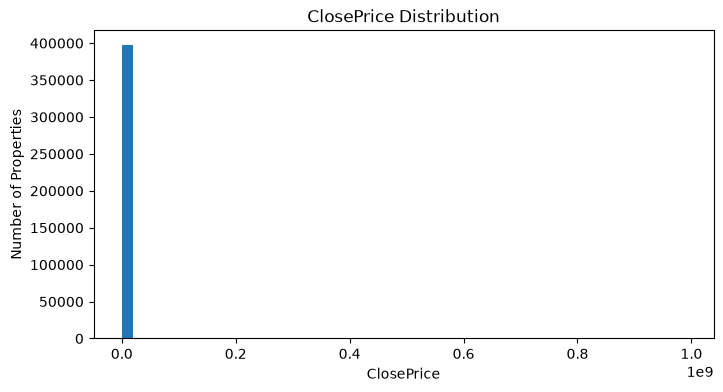

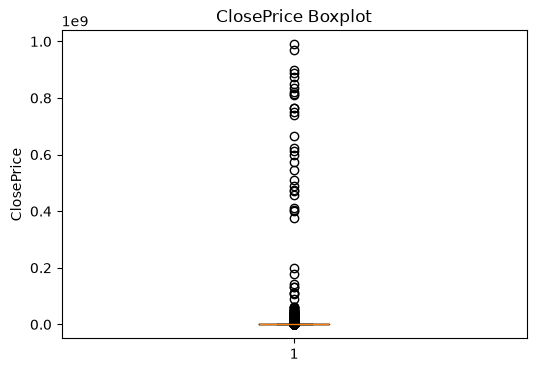

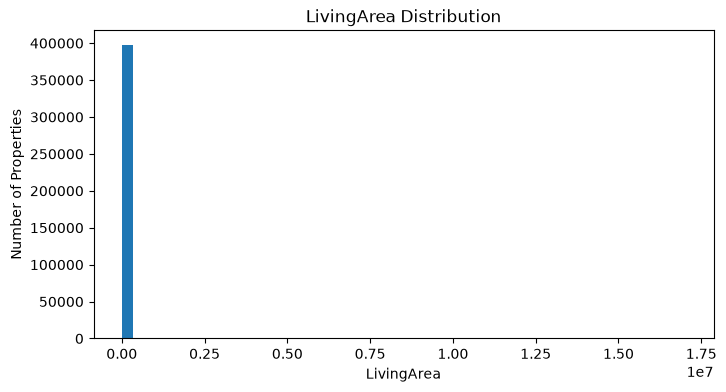

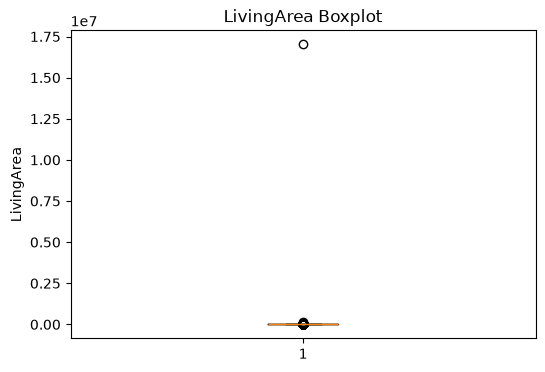

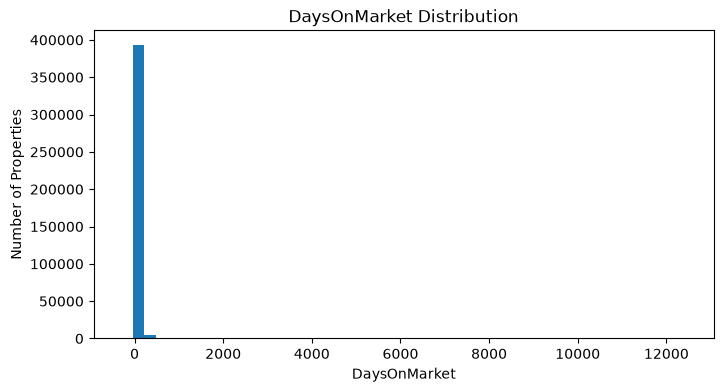

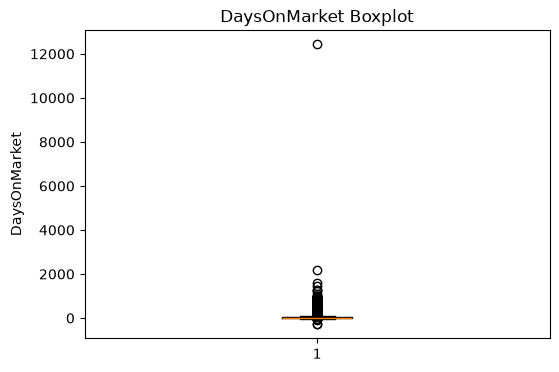

Week 2 initial analysis saved!


In [7]:
# Create histograms and boxplots
for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(sold[column].dropna(), bins=50)
    plt.title(column + " Distribution")
    plt.xlabel(column)
    plt.ylabel("Number of Properties")
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.boxplot(sold[column].dropna())
    plt.title(column + " Boxplot")
    plt.ylabel(column)
    plt.show()

# Save reports
Path("../reports").mkdir(exist_ok=True)

sold_missing.to_csv("../reports/sold_missing_report.csv")
listing_missing.to_csv("../reports/listings_missing_report.csv")
numeric_summary.to_csv("../reports/numeric_summary.csv")

print("Week 2 initial analysis saved!")

## Week 2: Data Exploration & Validation

### Goal
Check data quality, missing values, and housing market distributions.

### Findings
- **Median Close Price:** $820,000.
- **Median Living Area:** 1,641 sq ft.
- **Median Days on Market:** 19 days.
- **Missing Data:** 17 sold dataset columns have over 90% missing values.
- **Potential Outliers:** Some properties have unusually high prices, large living areas, or negative days on market.

### Takeaway
The typical sold property in this dataset has a price of around $820K and spends 19 days on the market. However, missing values and unusual records may affect the accuracy of future housing market analysis.

### Note
Potential outliers and missing values have been identified but not removed. Further data cleaning and validation are needed before continuing with mortgage rate integration.